<a href="https://colab.research.google.com/github/Subhajit-7/Fashion-MNIST/blob/main/ML_MINI_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the dataset using Python
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

# 2. Display Number of rows and columns
print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)

# 3. Display Column names (Showing first 10 for brevity)
print("\nColumn Names:", train_df.columns[:10].tolist(), "...", train_df.columns[-1])

# 4. Display Data types
print("\nData Types:\n", train_df.dtypes.value_counts())

# 5. Display First and last few records
print("\nFirst 5 records:\n", train_df.head())
print("\nLast 5 records:\n", train_df.tail())

# 6. Display Basic dataset information
print("\nBasic Dataset Information:")
train_df.info()

Training Data Shape: (60000, 785)
Testing Data Shape: (10000, 785)

Column Names: ['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9'] ... pixel784

Data Types:
 int64    785
Name: count, dtype: int64

First 5 records:
    label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0        

In [ ]:
# Separate features (X) and target labels (y)
X_train = train_df.drop('label', axis=1)
y_train = train_df['label']
X_test = test_df.drop('label', axis=1)
y_test = test_df['label']

# 1. Identify and handle missing values
print("Missing values in training set:", X_train.isnull().sum().sum())
# If missing values existed, we would drop or impute them. Here it should be 0.

# 2. Detect and handle duplicate records
duplicates = train_df.duplicated().sum()
print(f"Duplicate records found: {duplicates}")
if duplicates > 0:
    train_df = train_df.drop_duplicates()
    # Re-separate after dropping duplicates
    X_train = train_df.drop('label', axis=1)
    y_train = train_df['label']
    print("Duplicates removed.")

# 3. Identify numerical and categorical variables
# X_train contains numerical pixels; y_train contains categorical labels.

# 4. Perform feature scaling/normalization
# Pixel values range from 0 to 255. We normalize them to 0.0 - 1.0.
X_train_scaled = X_train.astype('float32') / 255.0
X_test_scaled = X_test.astype('float32') / 255.0

print("\nMax pixel value before scaling:", X_train.iloc[0].max())
print("Max pixel value after scaling:", X_train_scaled.iloc[0].max())

Missing values in training set: 0
Duplicate records found: 43
Duplicates removed.

Max pixel value before scaling: 255
Max pixel value after scaling: 1.0


/tmp/ipykernel_2106/3609702467.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette='viridis')


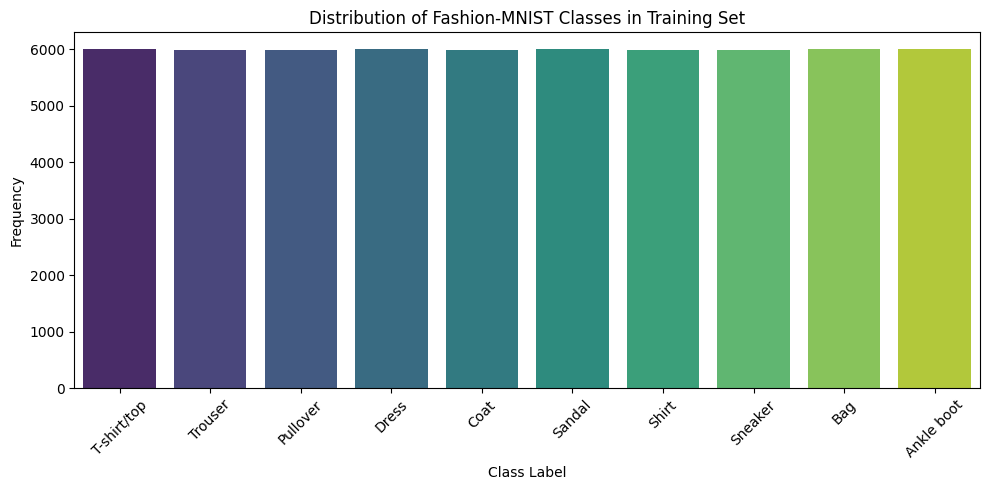

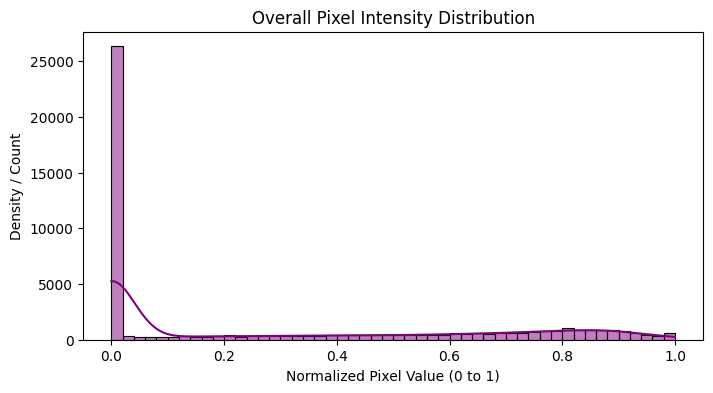

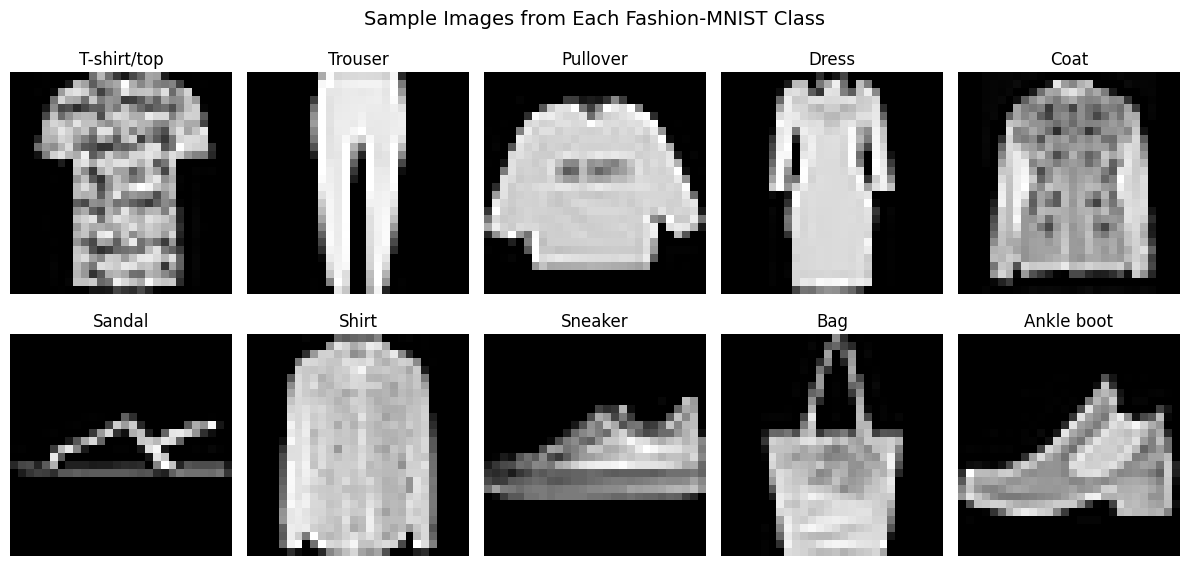

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Map for Fashion-MNIST class labels
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 1. Class Distribution Analysis (Bar Graph)
plt.figure(figsize=(10, 5))
sns.countplot(x=y_train, palette='viridis')
plt.title('Distribution of Fashion-MNIST Classes in Training Set')
plt.xlabel('Class Label')
plt.ylabel('Frequency')
plt.xticks(ticks=range(10), labels=class_names, rotation=45)
plt.tight_layout()
plt.show()

# Observation: The class distribution is perfectly balanced, with roughly 6,000 samples per class, meaning no class-weight adjustments are strictly required during model training.

# 2. Pixel Intensity Distribution Plot (Histogram)
# Flatten a subset of images to inspect overall pixel values (excluding background 0s if desired, or overall)
sample_pixels = X_train_scaled.values.flatten()
# Sample to save memory/speed up plotting
sample_pixels_subset = np.random.choice(sample_pixels, size=50000, replace=False)

plt.figure(figsize=(8, 4))
sns.histplot(sample_pixels_subset, bins=50, color='purple', kde=True)
plt.title('Overall Pixel Intensity Distribution')
plt.xlabel('Normalized Pixel Value (0 to 1)')
plt.ylabel('Density / Count')
plt.show()

# Observation: The bimodal-like distribution typically shows a large spike near 0 (representing the black background) and a spread across higher values representing the textured contours of the clothing items.

# 3. Sample Image Visualizations
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flatten()):
    # Find the first occurrence of class i
    idx = y_train[y_train == i].index[0]
    img = X_train.loc[idx].values.reshape(28, 28)

    ax.imshow(img, cmap='gray')
    ax.title.set_text(f"{class_names[i]}")
    ax.axis('off')

plt.suptitle('Sample Images from Each Fashion-MNIST Class', fontsize=14)
plt.tight_layout()
plt.show()

# Observation: Visual inspection confirms that items like T-shirts, trousers, and bags have distinct structural shapes, while categories like 'Shirt', 'Pullover', and 'Coat' share overlapping features, which may challenge the ANN during classification.

--- Descriptive Statistics of Aggregate Features ---
       Mean_Intensity  Max_Intensity  Std_Intensity
count    59957.000000   59957.000000   59957.000000
mean         0.286098       0.999671       0.320368
std          0.125812       0.001086       0.078503
min          0.019388       0.996078       0.064848
25%          0.186084       1.000000       0.262560
50%          0.272174       1.000000       0.331511
75%          0.381958       1.000000       0.385053
max          0.752236       1.000000       0.475351

Metric for Mean_Intensity:
  - Range: 0.7328
  - IQR: 0.1959
  - MAD: 0.1053
  - Variance: 0.0158
  - Standard Deviation: 0.1258

Metric for Max_Intensity:
  - Range: 0.0039
  - IQR: 0.0000
  - MAD: 0.0006
  - Variance: 0.0000
  - Standard Deviation: 0.0011

Metric for Std_Intensity:
  - Range: 0.4105
  - IQR: 0.1225
  - MAD: 0.0658
  - Variance: 0.0062
  - Standard Deviation: 0.0785

--- Pearson Correlation Coefficient (PCC) Matrix ---
                Mean_Intensity  Max_I

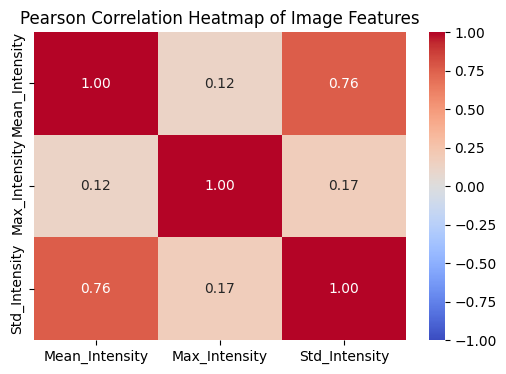


Outliers detected using IQR method: 24 samples
Outliers detected using Z-score (threshold > 3): 37 samples


/tmp/ipykernel_2106/3233322025.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2106/3233322025.py:84: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')


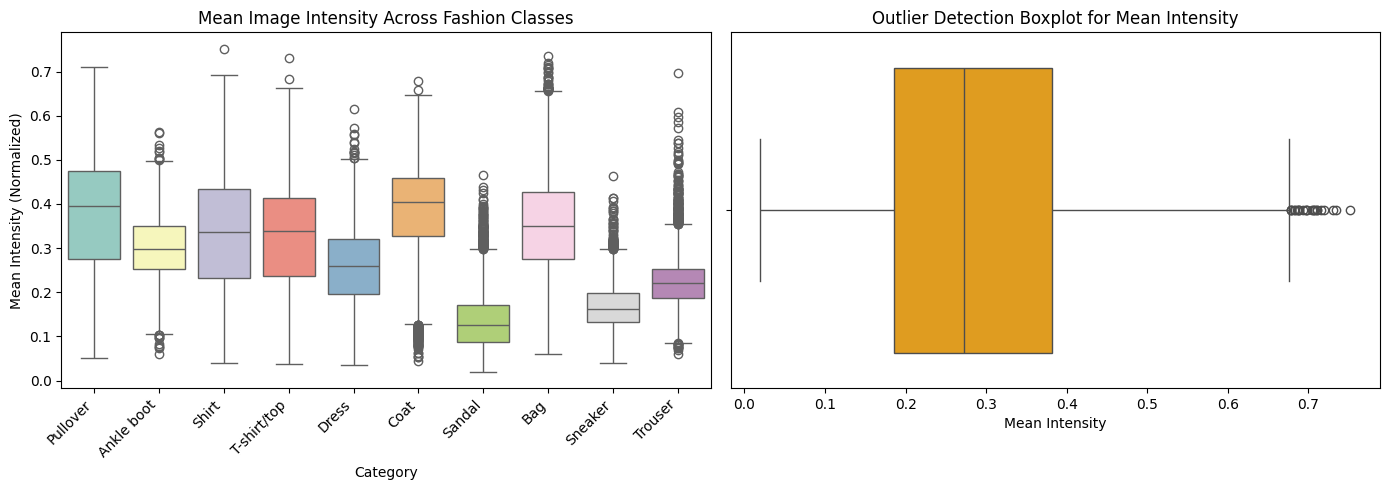

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# Create aggregate numerical features for statistical analysis
# 1. Mean pixel intensity per image
# 2. Max pixel intensity per image
train_stats_df = pd.DataFrame()
train_stats_df['Mean_Intensity'] = X_train_scaled.mean(axis=1)
train_stats_df['Max_Intensity'] = X_train_scaled.max(axis=1)
train_stats_df['Std_Intensity'] = X_train_scaled.std(axis=1)

print("--- Descriptive Statistics of Aggregate Features ---")
print(train_stats_df.describe())

# 1. Range, IQR, MAD, Variance, Standard Deviation
for col in train_stats_df.columns:
    data = train_stats_df[col]
    val_range = data.max() - data.min()
    iqr = data.quantile(0.75) - data.quantile(0.25)
    mad = np.mean(np.abs(data - data.mean()))
    variance = data.var()
    std_dev = data.std()

    print(f"\nMetric for {col}:")
    print(f"  - Range: {val_range:.4f}")
    print(f"  - IQR: {iqr:.4f}")
    print(f"  - MAD: {mad:.4f}")
    print(f"  - Variance: {variance:.4f}")
    print(f"  - Standard Deviation: {std_dev:.4f}")

# 2. Pearson Correlation Coefficient (PCC)
pcc_matrix = train_stats_df.corr(method='pearson')
print("\n--- Pearson Correlation Coefficient (PCC) Matrix ---")
print(pcc_matrix)

# Visualize PCC Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(pcc_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Pearson Correlation Heatmap of Image Features')
plt.show()

# 3. Outlier Detection
# Method A: IQR Method on Mean Intensity
Q1 = train_stats_df['Mean_Intensity'].quantile(0.25)
Q3 = train_stats_df['Mean_Intensity'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = train_stats_df[
    (train_stats_df['Mean_Intensity'] < lower_bound) |
    (train_stats_df['Mean_Intensity'] > upper_bound)
]
print(f"\nOutliers detected using IQR method: {len(iqr_outliers)} samples")

# Method B: Z-Score Method
z_scores = np.abs(stats.zscore(train_stats_df['Mean_Intensity']))
z_outliers_count = np.sum(z_scores > 3)
print(f"Outliers detected using Z-score (threshold > 3): {z_outliers_count} samples")

# Visualize Outliers with a Boxplot
train_stats_df['Label'] = y_train.values

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
train_stats_df['Category'] = train_stats_df['Label'].map(lambda x: class_names[x])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Class-wise Mean Intensity Distribution
sns.boxplot(
    data=train_stats_df,
    x='Category',
    y='Mean_Intensity',
    palette='Set3',
    ax=axes[0]
)
axes[0].set_title('Mean Image Intensity Across Fashion Classes')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_ylabel('Mean Intensity (Normalized)')

# Plot 2: Outlier Detection Boxplot
sns.boxplot(x=train_stats_df['Mean_Intensity'], color='orange', ax=axes[1])
axes[1].set_title('Outlier Detection Boxplot for Mean Intensity')
axes[1].set_xlabel('Mean Intensity')

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.callbacks import EarlyStopping

# 1. Prepare Validation Split from Training Data
# We can use validation_split in model.fit() or explicitly split using train_test_split.
# Here we will let Keras handle 20% of the training data as validation.

# 2. Define the ANN Architecture
model = Sequential([
    # Flatten layer to convert 28x28 images into a 784-element vector (if using unflattened arrays)
    # Since our X_train_scaled is already a 2D DataFrame of 784 columns,
    # we can pass it directly into a Dense layer, or reshape it if required.
    Flatten(input_shape=(784,)),

    # Hidden Layer 1 with ReLU activation
    Dense(128, activation='relu'),

    # Hidden Layer 2 with ReLU activation
    Dense(64, activation='relu'),

    # Output Layer with 10 classes and Softmax activation for multi-class classification
    Dense(10, activation='softmax')
])

# 3. Compile the Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary to inspect layers and parameter count
model.summary()

# 4. Define Hyperparameters and Callbacks
BATCH_SIZE = 64
EPOCHS = 20

# Early stopping to prevent overfitting if validation loss stops improving
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# 5. Train the Model
history = model.fit(
    X_train_scaled.values,
    y_train.values,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("\nModel Training Completed Successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8063 - loss: 0.5463 - val_accuracy: 0.8430 - val_loss: 0.4476
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8560 - loss: 0.3983 - val_accuracy: 0.8635 - val_loss: 0.3830
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8695 - loss: 0.3570 - val_accuracy: 0.8681 - val_loss: 0.3644
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8804 - loss: 0.3267 - val_accuracy: 0.8689 - val_loss: 0.3581
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8870 - loss: 0.3068 - val_accuracy: 0.8747 - val_loss: 0.3549
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8928 - loss: 0.2921 - val_accuracy: 0.8811 - val_loss: 0.3395
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8965 - loss: 0.2798 - val_accuracy: 0.8809 - val_loss: 0.3286
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9021 - loss: 0.2664 - val_accuracy: 0.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Overall Test Accuracy: 89.32%

--- Classification Report ---
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.85      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.81      0.84      0.83      1000
       Dress       0.92      0.91      0.91      1000
        Coat       0.83      0.83      0.83      1000
      Sandal       0.98      0.93      0.95      1000
       Shirt       0.73      0.70      0.72      1000
     Sneaker       0.92      0.96      0.94      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.95      0.96      0.95      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



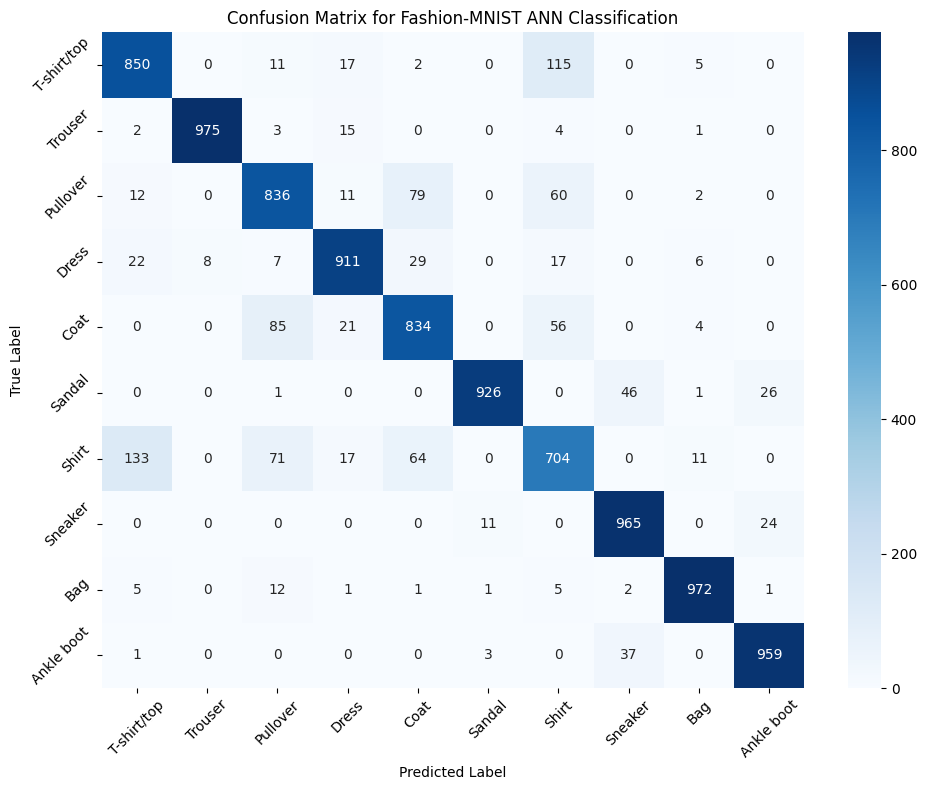

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate Predictions on the Test Set
y_pred_probs = model.predict(X_test_scaled.values)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Calculate Overall Accuracy
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Test Accuracy: {test_accuracy * 100:.2f}%\n")

# 3. Classification Report (Precision, Recall, F1-Score per class)
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=class_names))

# 4. Confusion Matrix Calculation and Visualization
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Fashion-MNIST ANN Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()

# Observation: The confusion matrix will typically show high accuracy on distinct items like trousers and bags, with minor confusion clusters between upper-body garments like T-shirts, pullovers, and shirts due to similar visual layouts.

Macro-Average ROC-AUC Score: 0.9925


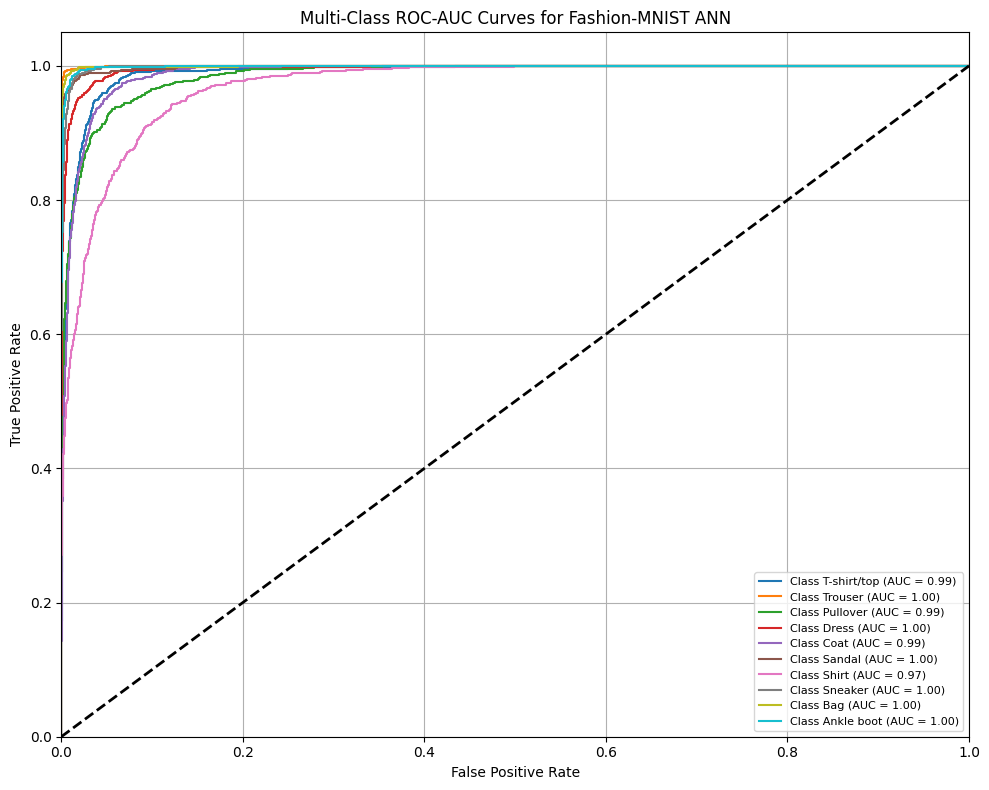

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# 1. Binarize the test labels for multi-class ROC-AUC calculation
y_test_binarized = label_binarize(y_test, classes=range(10))

# 2. Calculate Macro-Average ROC-AUC Score
roc_auc = roc_auc_score(y_test_binarized, y_pred_probs, multi_class='ovr', average='macro')
print(f"Macro-Average ROC-AUC Score: {roc_auc:.4f}")

# 3. Plot ROC curves for each class
plt.figure(figsize=(10, 8))

for i in range(10):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_pred_probs[:, i])
    roc_auc_class = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {class_names[i]} (AUC = {roc_auc_class:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC-AUC Curves for Fashion-MNIST ANN')
plt.legend(loc="lower right", fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

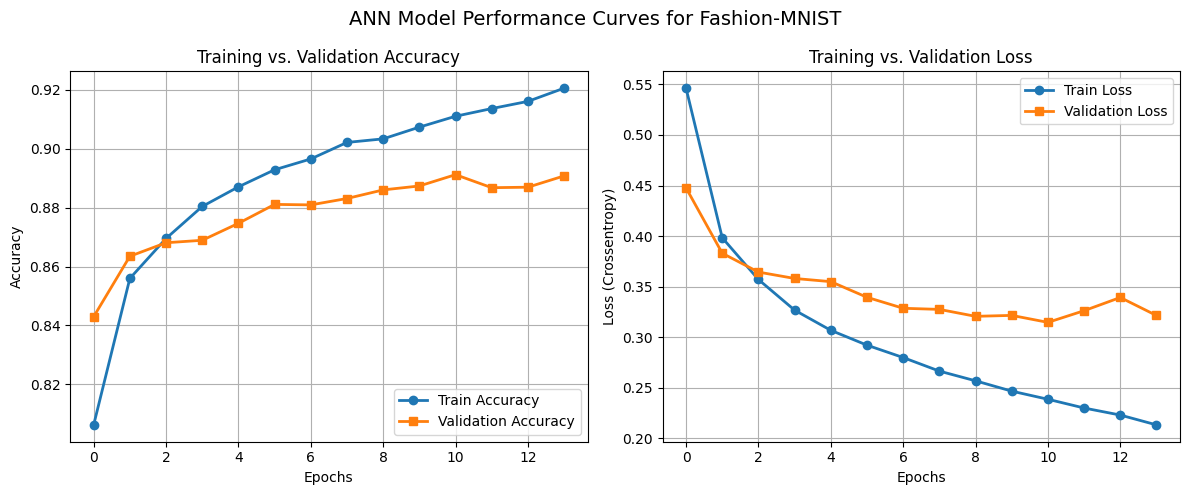

In [ ]:
import matplotlib.pyplot as plt

# Create a figure with two subplots: Accuracy and Loss
plt.figure(figsize=(12, 5))

# 1. Training vs. Validation Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2, marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, marker='s')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# 2. Training vs. Validation Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2, marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2, marker='s')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (Crossentropy)')
plt.legend(loc='upper right')
plt.grid(True)

plt.suptitle('ANN Model Performance Curves for Fashion-MNIST', fontsize=14)
plt.tight_layout()
plt.show()

# Observation: The curves typically show rapid learning in the first few epochs, followed by a gradual flattening (convergence). Early stopping ensures training halts before divergence occurs between training and validation metrics.